# Matching Experiment: SequenceMatcher vs rapidfuzz

Side-by-side comparison of the current `difflib.SequenceMatcher` approach and a `rapidfuzz.token_set_ratio` approach for matching local audio filenames to Spotify track metadata.

**Primary test set:** `music/Set House Play Around/` (38 files)  
**Secondary sets:** `chill set/`, `techno/`, `trance_tecno/`  
**Reference:** all tracks in `spotify_snapshot.json`

In [1]:
# ── Cell 1: Imports & paths ───────────────────────────────────────────────
import json
import re
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from rapidfuzz import fuzz as rf

PROJECT_ROOT = Path("../")
SNAPSHOT_PATH = PROJECT_ROOT / "spotify_snapshot.json"
MUSIC_ROOT = PROJECT_ROOT / "music"

AUDIO_EXT = {".mp3", ".flac", ".wav", ".aiff", ".aif", ".m4a", ".ogg"}

# Unsorted folders to analyse
UNSORTED_FOLDERS = [
    "Set House Play Around",
    "chill set",
    "techno",
    "trance_tecno",
]

print("Imports OK")

Imports OK


In [2]:
# ── Cell 2: Load Spotify reference tracks ────────────────────────────────
snapshot = json.loads(SNAPSHOT_PATH.read_text())

all_tracks = []
for pl in snapshot["playlists"]:
    for t in pl["tracks"]:
        all_tracks.append({
            "spotify_id": t["id"],
            "artist": t["artist"],
            "title": t["title"],
            "playlist": pl["playlist_name"],
            "subgenre": pl["schema_subgenre"],
        })

# Deduplicate by spotify_id (same track can appear in multiple playlists)
seen = set()
unique_tracks = []
for t in all_tracks:
    if t["spotify_id"] not in seen:
        seen.add(t["spotify_id"])
        unique_tracks.append(t)

ref_df = pd.DataFrame(unique_tracks)
print(f"Loaded {len(ref_df)} unique Spotify tracks across {len(snapshot['playlists'])} playlists")
ref_df.head()

Loaded 303 unique Spotify tracks across 25 playlists


,spotify_id,artist,title,playlist,subgenre
0,0sVGeRw2BwO6rSmODLkm1T,Mandragora,Drama,psytrance,Psytrance
1,0Nys24CG1nGh9AKBrF9GD0,Mausio,BEAUTY,High Tech,High Tech
2,7eKYSWYqhWLSsrh9JkAtvY,Thomas Schumacher,Fangbanger - Victor Ruiz Remix,Peak-time techno,Peak-Time Techno
3,38IjbIQrTYSx1q26ToyYqp,Joyhauser,Running Away,Peak-time techno,Peak-Time Techno
4,3gvYQtB3CygqRQWjjTWkhs,Mark Reeve,Focus,Peak-time techno,Peak-Time Techno


In [3]:
# ── Cell 3: Load local files ──────────────────────────────────────────────
local_files = {}  # folder_name -> [stem, ...]
for folder_name in UNSORTED_FOLDERS:
    folder = MUSIC_ROOT / folder_name
    if not folder.exists():
        print(f"  [SKIP] {folder_name} — folder not found")
        continue
    stems = [
        f.stem
        for f in sorted(folder.iterdir())
        if f.is_file() and f.suffix.lower() in AUDIO_EXT
    ]
    local_files[folder_name] = stems
    print(f"  {folder_name}: {len(stems)} files")

total_files = sum(len(v) for v in local_files.values())
print(f"\nTotal local files to analyse: {total_files}")

  Set House Play Around: 38 files
  chill set: 8 files
  techno: 2 files
  trance_tecno: 119 files

Total local files to analyse: 167


In [4]:
# ── Cell 4: Shared cleaning (applied to BOTH filename and Spotify strings) ─

# Copied verbatim from scripts/03b_reconcile_unsorted.py
RE_TRACK_NUM  = re.compile(r"^[\d]{1,3}[-_\s]+")
RE_SITE_PREFIX = re.compile(r"^[A-Za-z0-9]+\.[a-zA-Z]{2,4}\s*-\s*")
RE_MIX_SUFFIX  = re.compile(
    r"\s*[\(\[][^\)\]]*\b(mix|edit|remix|dub|vip|radio|original|extended|club|version|rework|cut|instrumental)\b[^\)\]]*[\)\]]",
    re.IGNORECASE,
)
# NEW: strip dash-separated remix/mix/edit tails  e.g.  "- Original Mix"  "- Radio Edit"
RE_DASH_MIX   = re.compile(
    r"\s*-\s*[^-]*\b(mix|edit|remix|dub|vip|radio|original|extended|club|version|rework|cut|instrumental)\b[^-]*$",
    re.IGNORECASE,
)
# NEW: strip feat / ft / with  e.g.  "(feat. AlunaGeorge)"  "ft. Robin S."
RE_FEAT       = re.compile(
    r"[\(\[]?(?:feat\.?|ft\.?|with|&)\s+[^\)\]]*[\)\]]?",
    re.IGNORECASE,
)


def normalize(s: str) -> str:
    s = s.lower()
    s = re.sub(r"[^a-z0-9\s]", "", s)
    return re.sub(r"\s+", " ", s).strip()


def clean(s: str) -> str:
    """Deep-clean a string for matching: strip mix suffixes, feat tags, normalise."""
    s = RE_MIX_SUFFIX.sub("", s)
    s = RE_DASH_MIX.sub("", s)
    s = RE_FEAT.sub("", s)
    return normalize(s).strip()


def preprocess_stem(stem: str):
    """Return (candidate_artist, candidate_title) from a filename stem."""
    s = stem.replace("_", " ")
    had_site_prefix = bool(RE_SITE_PREFIX.match(s))
    s = RE_SITE_PREFIX.sub("", s)
    s = RE_TRACK_NUM.sub("", s)
    s = RE_MIX_SUFFIX.sub("", s)
    s = s.strip(" -")
    if " - " not in s:
        return "", s.strip()
    if had_site_prefix:
        title, artist = s.rsplit(" - ", 1)
        return artist.strip(), title.strip()
    parts = s.split(" - ", 1)
    return parts[0].strip(), parts[1].strip()


# Spot-check
examples = [
    "SpotiDownloader.com - Enough to Believe - Jamie Jones Remix - Bob Moses",
    "Lost Frequencies - Rise (Extended Deluxe Mix)",
    "James Hype, Shamiya Battles - 7 Seconds (feat. Shamiya Battles) (Original Mix)",
    "Vintage Culture, James Hype - You Give Me A Feeling (Original Mix)",
]
for ex in examples:
    a, t = preprocess_stem(ex)
    print(f"artist={a!r:30s}  title={t!r}")

artist='Bob Moses'                     title='Enough to Believe - Jamie Jones Remix'
artist='Lost Frequencies'              title='Rise'
artist='James Hype, Shamiya Battles'   title='7 Seconds (feat. Shamiya Battles)'
artist='Vintage Culture, James Hype'   title='You Give Me A Feeling'


In [5]:
# ── Cell 5: Two matchers ──────────────────────────────────────────────────

# --- Baseline: current production matcher (difflib) ---
def _title_score_seq(cand: str, ref: str) -> float:
    s_full = SequenceMatcher(None, normalize(cand), normalize(ref)).ratio()
    ref_base = ref.split(" - ", 1)[0] if " - " in ref else ref
    s_base = SequenceMatcher(None, normalize(cand), normalize(ref_base)).ratio()
    return max(s_full, s_base)

def match_current(cand_artist, cand_title, ref_artist, ref_title):
    a1 = SequenceMatcher(None, normalize(cand_artist), normalize(ref_artist)).ratio()
    t1 = _title_score_seq(cand_title, ref_title)
    a2 = SequenceMatcher(None, normalize(cand_title), normalize(ref_artist)).ratio()
    t2 = _title_score_seq(cand_artist, ref_title)
    if a1 + t1 >= a2 + t2:
        return a1, t1
    return a2, t2


# --- Challenger: rapidfuzz token_set_ratio ---
def match_rapidfuzz(cand_artist, cand_title, ref_artist, ref_title):
    # Clean both sides before comparing
    ca = clean(cand_artist);  ra = clean(ref_artist)
    ct = clean(cand_title);   rt = clean(ref_title)

    a1 = rf.token_set_ratio(ca, ra) / 100
    t1 = rf.token_set_ratio(ct, rt) / 100
    # Swapped order
    a2 = rf.token_set_ratio(ct, ra) / 100
    t2 = rf.token_set_ratio(ca, rt) / 100
    if a1 + t1 >= a2 + t2:
        return a1, t1
    return a2, t2


# Sanity check on known examples
checks = [
    ("Bob Moses",         "Enough to Believe - Jamie Jones Remix",  "Bob Moses",       "Enough to Believe - Jamie Jones Remix"),
    ("Lost Frequencies",  "Rise",                                   "Lost Frequencies","Rise - Deluxe Mix"),
    ("Vintage Culture",   "You Give Me A Feeling",                  "Vintage Culture", "You Give Me A Feeling"),
]
print(f"{'Case':<45} {'Seq(a,t)':<18} {'RF(a,t)'}")
print("-" * 80)
for ca, ct, ra, rt in checks:
    sa, st = match_current(ca, ct, ra, rt)
    ra_, rt_ = match_rapidfuzz(ca, ct, ra, rt)
    label = f"{ca} – {ct[:25]}"
    print(f"{label:<45} seq({sa:.2f},{st:.2f})  rf({ra_:.2f},{rt_:.2f})")

Case                                          Seq(a,t)           RF(a,t)
--------------------------------------------------------------------------------
Bob Moses – Enough to Believe - Jamie         seq(1.00,1.00)  rf(1.00,1.00)
Lost Frequencies – Rise                       seq(1.00,1.00)  rf(1.00,1.00)
Vintage Culture – You Give Me A Feeling       seq(1.00,1.00)  rf(1.00,1.00)


In [6]:
# ── Cell 6: Build score matrix (all files × all Spotify tracks) ───────────
ARTIST_THRESHOLD = 0.80
TITLE_THRESHOLD  = 0.85

rows = []
for folder_name, stems in local_files.items():
    for stem in stems:
        cand_artist, cand_title = preprocess_stem(stem)
        best_seq = {"artist": 0.0, "title": 0.0, "ref_artist": "", "ref_title": "", "subgenre": ""}
        best_rf  = {"artist": 0.0, "title": 0.0, "ref_artist": "", "ref_title": "", "subgenre": ""}

        for _, ref in ref_df.iterrows():
            sa, st = match_current(cand_artist, cand_title, ref["artist"], ref["title"])
            ra, rt = match_rapidfuzz(cand_artist, cand_title, ref["artist"], ref["title"])

            # Track best combined score for each method
            if sa + st > best_seq["artist"] + best_seq["title"]:
                best_seq = {"artist": sa, "title": st,
                            "ref_artist": ref["artist"], "ref_title": ref["title"],
                            "subgenre": ref["subgenre"]}
            if ra + rt > best_rf["artist"] + best_rf["title"]:
                best_rf  = {"artist": ra, "title": rt,
                            "ref_artist": ref["artist"], "ref_title": ref["title"],
                            "subgenre": ref["subgenre"]}

        seq_match = best_seq["artist"] >= ARTIST_THRESHOLD and best_seq["title"] >= TITLE_THRESHOLD
        rf_match  = best_rf["artist"]  >= ARTIST_THRESHOLD and best_rf["title"]  >= TITLE_THRESHOLD

        rows.append({
            "folder":           folder_name,
            "filename":         stem,
            "cand_artist":      cand_artist,
            "cand_title":       cand_title,
            # Best Seq match
            "seq_ref_artist":   best_seq["ref_artist"],
            "seq_ref_title":    best_seq["ref_title"],
            "seq_artist_score": round(best_seq["artist"], 3),
            "seq_title_score":  round(best_seq["title"], 3),
            "seq_match":        seq_match,
            "seq_subgenre":     best_seq["subgenre"] if seq_match else "",
            # Best RF match
            "rf_ref_artist":    best_rf["ref_artist"],
            "rf_ref_title":     best_rf["ref_title"],
            "rf_artist_score":  round(best_rf["artist"], 3),
            "rf_title_score":   round(best_rf["title"], 3),
            "rf_match":         rf_match,
            "rf_subgenre":      best_rf["subgenre"] if rf_match else "",
        })

matrix = pd.DataFrame(rows)
print(f"Score matrix built: {len(matrix)} files × {len(ref_df)} tracks")
print(f"\nMatched (Seq): {matrix['seq_match'].sum()} / {len(matrix)}")
print(f"Matched (RF):  {matrix['rf_match'].sum()} / {len(matrix)}")

Score matrix built: 167 files × 303 tracks

Matched (Seq): 0 / 167
Matched (RF):  19 / 167


In [7]:
# ── Cell 7: Per-file best-match table (Set House Play Around) ─────────────
display_cols = [
    "filename", "cand_artist", "cand_title",
    "seq_ref_artist", "seq_ref_title", "seq_artist_score", "seq_title_score", "seq_match",
    "rf_ref_artist",  "rf_ref_title",  "rf_artist_score",  "rf_title_score",  "rf_match",
]

def flag(row):
    if row["seq_match"] and row["rf_match"]:     return "both"
    if row["rf_match"] and not row["seq_match"]: return "rf_only ✓"
    if row["seq_match"] and not row["rf_match"]: return "seq_only"
    return "neither"

matrix["verdict"] = matrix.apply(flag, axis=1)

shpa = matrix[matrix["folder"] == "Set House Play Around"].copy()

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.max_rows", 60)

print(f"Set House Play Around — {len(shpa)} files")
print(shpa[["filename", "seq_artist_score", "seq_title_score", "seq_match",
            "rf_artist_score", "rf_title_score", "rf_match", "verdict"
           ]].to_string(index=False))

Set House Play Around — 38 files
                                                                                 filename  seq_artist_score  seq_title_score  seq_match  rf_artist_score  rf_title_score  rf_match   verdict
                           02. Kungs - Never Going Home (Lost Frequencies Extended Remix)             0.769            1.000      False            1.000           1.000      True rf_only ✓
                                                                 03. Zhu - In the Morning             0.667            1.000      False            1.000           1.000      True rf_only ✓
                                                                      07 Around the World             0.000            1.000      False            0.000           1.000     False   neither
                                                                              08 - Jungle             0.000            1.000      False            0.000           1.000     False   neither
                      

In [8]:
# ── Cell 8: Disagreements — what RF catches that Seq misses ──────────────
rf_wins = matrix[(matrix["rf_match"]) & (~matrix["seq_match"])]
seq_wins = matrix[(matrix["seq_match"]) & (~matrix["rf_match"])]

print(f"RF matches that Seq misses: {len(rf_wins)}")
if len(rf_wins):
    print(rf_wins[["folder", "filename", "rf_ref_artist", "rf_ref_title",
                   "rf_artist_score", "rf_title_score",
                   "seq_artist_score", "seq_title_score"]].to_string(index=False))

print(f"\nSeq matches that RF misses: {len(seq_wins)}")
if len(seq_wins):
    print(seq_wins[["folder", "filename", "seq_ref_artist", "seq_ref_title",
                    "seq_artist_score", "seq_title_score",
                    "rf_artist_score", "rf_title_score"]].to_string(index=False))

RF matches that Seq misses: 19
               folder                                                                                  filename    rf_ref_artist                                   rf_ref_title  rf_artist_score  rf_title_score  seq_artist_score  seq_title_score
Set House Play Around                            02. Kungs - Never Going Home (Lost Frequencies Extended Remix)            Kungs      Never Going Home - Lost Frequencies Remix              1.0             1.0             0.769            1.000
Set House Play Around                                                                  03. Zhu - In the Morning              ZHU                                 In the Morning              1.0             1.0             0.667            1.000
Set House Play Around                                   35. Kisch - Love All Day (feat. Leela D) (Extended Mix)            Kisch                    Love All Day - Extended Mix              1.0             1.0             0.769           

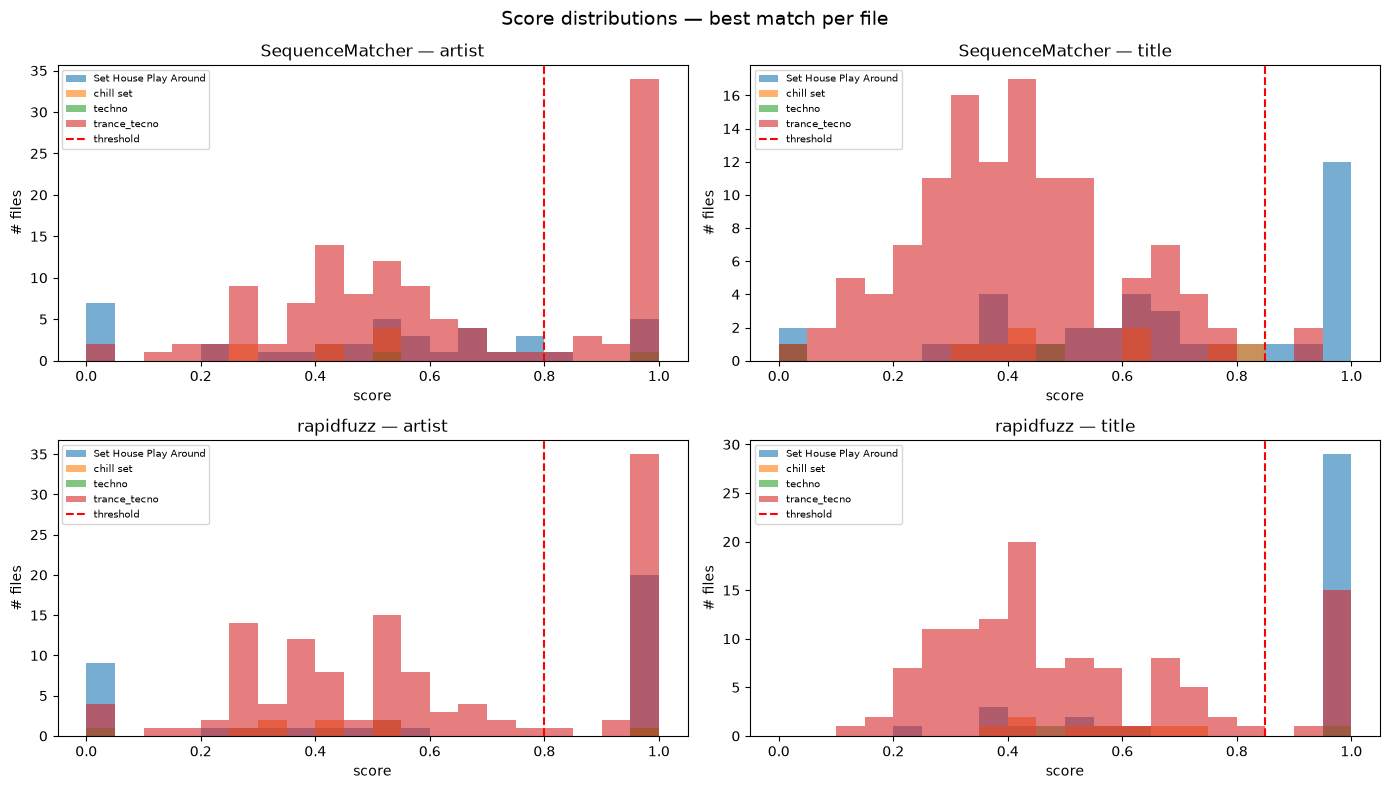

Saved score_distributions.png


In [9]:
# ── Cell 9: Score distributions ───────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Score distributions — best match per file", fontsize=14)

for ax, col, label in [
    (axes[0, 0], "seq_artist_score", "SequenceMatcher — artist"),
    (axes[0, 1], "seq_title_score",  "SequenceMatcher — title"),
    (axes[1, 0], "rf_artist_score",  "rapidfuzz — artist"),
    (axes[1, 1], "rf_title_score",   "rapidfuzz — title"),
]:
    for folder, grp in matrix.groupby("folder"):
        ax.hist(grp[col], bins=20, range=(0, 1), alpha=0.6, label=folder)
    ax.axvline(ARTIST_THRESHOLD if "artist" in col else TITLE_THRESHOLD,
               color="red", linestyle="--", linewidth=1.5, label="threshold")
    ax.set_title(label)
    ax.set_xlabel("score")
    ax.set_ylabel("# files")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig("score_distributions.png", dpi=120)
plt.show()
print("Saved score_distributions.png")

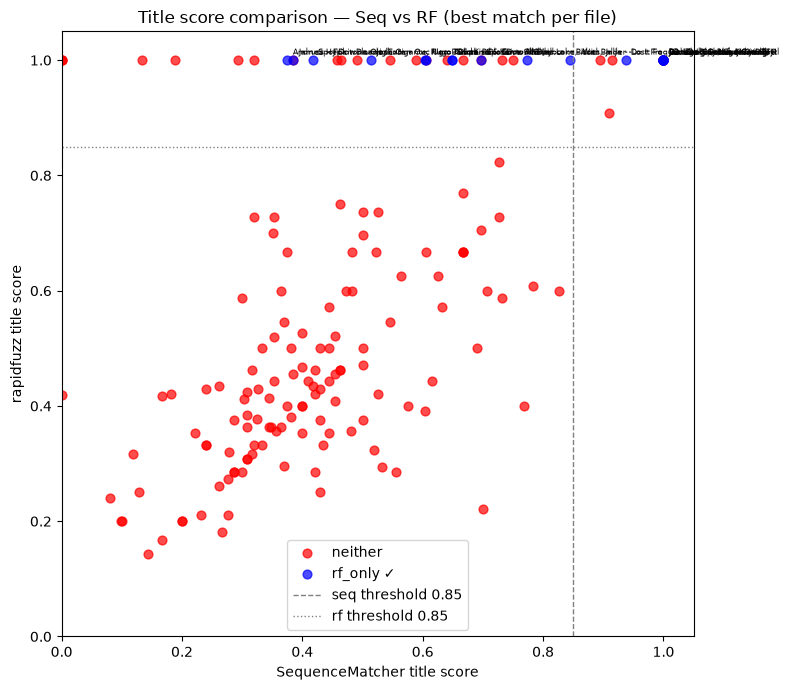

Saved seq_vs_rf_scatter.png


In [10]:
# ── Cell 10: Seq vs RF scatter (title scores) ─────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))

colors = {"both": "green", "rf_only ✓": "blue", "seq_only": "orange", "neither": "red"}
for verdict, grp in matrix.groupby("verdict"):
    ax.scatter(grp["seq_title_score"], grp["rf_title_score"],
               c=colors.get(verdict, "grey"), label=verdict, alpha=0.7, s=40)

ax.axvline(TITLE_THRESHOLD, color="grey", linestyle="--", linewidth=1, label=f"seq threshold {TITLE_THRESHOLD}")
ax.axhline(TITLE_THRESHOLD, color="grey", linestyle=":",  linewidth=1, label=f"rf threshold {TITLE_THRESHOLD}")
ax.set_xlabel("SequenceMatcher title score")
ax.set_ylabel("rapidfuzz title score")
ax.set_title("Title score comparison — Seq vs RF (best match per file)")
ax.legend()
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)

# Label outlier points (rf matches but seq doesn't)
for _, row in matrix[matrix["verdict"] == "rf_only ✓"].iterrows():
    ax.annotate(Path(row["filename"]).name[:25],
                xy=(row["seq_title_score"], row["rf_title_score"]),
                fontsize=6, ha="left", xytext=(4, 4), textcoords="offset points")

plt.tight_layout()
plt.savefig("seq_vs_rf_scatter.png", dpi=120)
plt.show()
print("Saved seq_vs_rf_scatter.png")

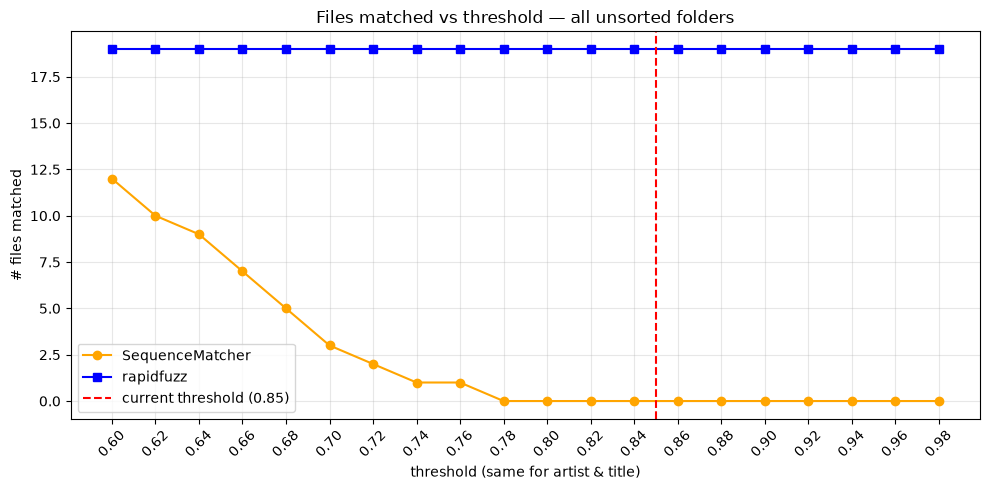

Saved threshold_sweep.png
 threshold  seq_matched  rf_matched  rf_gain
      0.60           12          19        7
      0.62           10          19        9
      0.64            9          19       10
      0.66            7          19       12
      0.68            5          19       14
      0.70            3          19       16
      0.72            2          19       17
      0.74            1          19       18
      0.76            1          19       18
      0.78            0          19       19
      0.80            0          19       19
      0.82            0          19       19
      0.84            0          19       19
      0.86            0          19       19
      0.88            0          19       19
      0.90            0          19       19
      0.92            0          19       19
      0.94            0          19       19
      0.96            0          19       19
      0.98            0          19       19


In [11]:
# ── Cell 11: Threshold sweep ──────────────────────────────────────────────
thresholds = [t / 100 for t in range(60, 100, 2)]

seq_counts = []
rf_counts  = []
for thr in thresholds:
    seq_counts.append(((matrix["seq_artist_score"] >= thr) & (matrix["seq_title_score"] >= thr)).sum())
    rf_counts.append( ((matrix["rf_artist_score"]  >= thr) & (matrix["rf_title_score"]  >= thr)).sum())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, seq_counts, marker="o", label="SequenceMatcher", color="orange")
ax.plot(thresholds, rf_counts,  marker="s", label="rapidfuzz",        color="blue")
ax.axvline(TITLE_THRESHOLD, color="red", linestyle="--", label=f"current threshold ({TITLE_THRESHOLD})")
ax.set_xlabel("threshold (same for artist & title)")
ax.set_ylabel("# files matched")
ax.set_title("Files matched vs threshold — all unsorted folders")
ax.legend()
ax.set_xticks(thresholds)
ax.set_xticklabels([f"{t:.2f}" for t in thresholds], rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("threshold_sweep.png", dpi=120)
plt.show()
print("Saved threshold_sweep.png")

# Print the table
sweep_df = pd.DataFrame({"threshold": thresholds, "seq_matched": seq_counts, "rf_matched": rf_counts})
sweep_df["rf_gain"] = sweep_df["rf_matched"] - sweep_df["seq_matched"]
print(sweep_df.to_string(index=False))

In [12]:
# ── Cell 12: Unmatched deep-dive ──────────────────────────────────────────
# Files where neither method finds a match — show top-3 candidates from each
unmatched = matrix[(~matrix["seq_match"]) & (~matrix["rf_match"])].copy()
print(f"Unmatched by BOTH methods: {len(unmatched)} files\n")

for _, row in unmatched.iterrows():
    print(f"FILE: {row['folder']}/{row['filename']}")
    print(f"  parsed → artist={row['cand_artist']!r}  title={row['cand_title']!r}")
    print(f"  best Seq → {row['seq_ref_artist']} – {row['seq_ref_title']}")
    print(f"             artist={row['seq_artist_score']:.3f}  title={row['seq_title_score']:.3f}")
    print(f"  best RF  → {row['rf_ref_artist']} – {row['rf_ref_title']}")
    print(f"             artist={row['rf_artist_score']:.3f}  title={row['rf_title_score']:.3f}")
    print()

Unmatched by BOTH methods: 148 files

FILE: Set House Play Around/07 Around the World
  parsed → artist=''  title='Around the World'
  best Seq → Daft Punk – Around the World
             artist=0.000  title=1.000
  best RF  → Daft Punk – Around the World
             artist=0.000  title=1.000

FILE: Set House Play Around/08 - Jungle
  parsed → artist=''  title='Jungle'
  best Seq → Fred again.. – Jungle
             artist=0.000  title=1.000
  best RF  → Fred again.. – Jungle
             artist=0.000  title=1.000

FILE: Set House Play Around/1-06 Lamur (Henry Saiz Mix Edit)
  parsed → artist=''  title='06 Lamur'
  best Seq → LAMMER – Time To Move
             artist=0.571  title=0.000
  best RF  → Guy J – Lamur (Henry Saiz Remix)
             artist=0.000  title=1.000

FILE: Set House Play Around/1. Hurting
  parsed → artist=''  title='1. Hurting'
  best Seq → umbraid – Heartbreaking
             artist=0.000  title=0.545
  best RF  → SG Lewis – Hurting (feat. AlunaGeorge)
          

               folder  total  seq_matched  rf_matched  seq_pct  rf_pct  rf_gain
Set House Play Around     38            0          17      0.0    44.7       17
            chill set      8            0           0      0.0     0.0        0
               techno      2            0           0      0.0     0.0        0
         trance_tecno    119            0           2      0.0     1.7        2


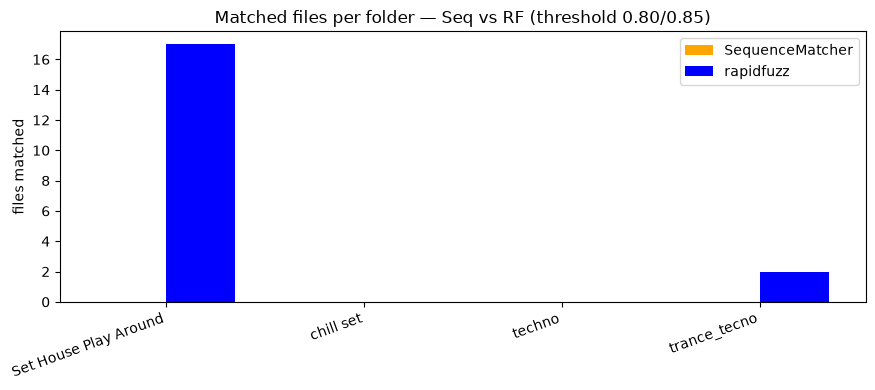

Saved per_folder_summary.png


In [13]:
# ── Cell 13: Per-folder summary ───────────────────────────────────────────
summary = matrix.groupby("folder").agg(
    total=("filename", "count"),
    seq_matched=("seq_match", "sum"),
    rf_matched=("rf_match", "sum"),
).reset_index()
summary["seq_pct"] = (summary["seq_matched"] / summary["total"] * 100).round(1)
summary["rf_pct"]  = (summary["rf_matched"]  / summary["total"] * 100).round(1)
summary["rf_gain"] = summary["rf_matched"] - summary["seq_matched"]

print(summary.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(summary))
w = 0.35
ax.bar([i - w/2 for i in x], summary["seq_matched"], width=w, label="SequenceMatcher", color="orange")
ax.bar([i + w/2 for i in x], summary["rf_matched"],  width=w, label="rapidfuzz",        color="blue")
ax.set_xticks(list(x))
ax.set_xticklabels(summary["folder"], rotation=20, ha="right")
ax.set_ylabel("files matched")
ax.set_title("Matched files per folder — Seq vs RF (threshold 0.80/0.85)")
ax.legend()
plt.tight_layout()
plt.savefig("per_folder_summary.png", dpi=120)
plt.show()
print("Saved per_folder_summary.png")